# Классификация

Считаем данные

In [18]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

path_file = "./Titanic-Dataset.csv"

df = pd.read_csv(path_file)

display(df)

print("With empty:")
display(df.columns[df.isna().any()])


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


With empty:


Index(['Age', 'Cabin', 'Embarked'], dtype='str')

После анализа данных разбили one-hot: пол, откуда сели, статус (из имени). Выкинули имя и номер кабины - вместо номера: был или нет. Для missing: age - медиана в соответствующей группе пассажира, embarked - наиболее частый из остальных, Cabin -> HasCabin. (ниже в препроцессоре)

Разобьём выборку в отношении 80-20.

In [19]:
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
TEST_SIZE = 0.2

# df = df.drop_duplicates()

X = df.drop(columns=['Survived'])
y = df['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print(X_train.shape, X_test.shape)


(712, 11) (179, 11)


## Preprocess

In [20]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


class TitanicProprocessor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): # type: ignore
        temp_df = X.copy() # type: ignore

        temp_df["Title"] = temp_df["Name"].str.extract(r",\s*([^\.]+)\.") # type: ignore
        temp_df["Title"] = (
            temp_df["Title"]
            .replace(["Mlle", "Ms"], "Miss") # type: ignore
            .replace("Mme", "Mrs") # type: ignore
            .replace(["Lady","Countess","Capt","Col","Don","Dr","Major",
                    "Rev","Sir","Jonkheer","Dona", "the Countess"], "Rare")
        )

        self.age_medians_ = temp_df.groupby(["Sex", "Pclass", "Title"])["Age"].median() # type: ignore
        self.global_age_median_ = temp_df["Age"].median() # type: ignore
        self.embarked_mode_= temp_df["Embarked"].mode()[0] # type: ignore

        df = self._transform(X) # type: ignore

        self.feature_names_out_ = df.columns.tolist()

        return self

    def transform(self, X: pd.DataFrame):
        df = self._transform(X)

        df = df.reindex(columns=self.feature_names_out_, fill_value=0)

        return df

    def _transform(self, X: pd.DataFrame):
        df = X.copy()
        df["Title"] = df["Name"].str.extract(r",\s*([^\.]+)\.")

        df["Title"] = (
            df["Title"]
            .replace(["Mlle", "Ms"], "Miss")
            .replace("Mme", "Mrs")
            .replace(["Lady","Countess","Capt","Col","Don","Dr","Major",
                    "Rev","Sir","Jonkheer","Dona", "the Countess"], "Rare")
        )

        df["Embarked"] = df["Embarked"].fillna(self.embarked_mode_) # type: ignore
        """
        df["Age"] = df.groupby(["Sex", "Pclass", "Title"])["Age"].transform(
            lambda s: s.fillna(s.median())
        )
        """

        def fill_age(row):
            if pd.isna(row["Age"]):
                key = (row["Sex"], row["Pclass"], row["Title"])
                if key in self.age_medians_.index and not pd.isna(self.age_medians_[key]):
                    return self.age_medians_[key]
                return self.global_age_median_
            return row["Age"]

        df["Age"] = df.apply(fill_age, axis=1)

        df["Age"] = df["Age"].fillna(self.global_age_median_)

        df["HasCabin"] = df["Cabin"].notna()
        df = df.drop(columns=["Cabin", "PassengerId", "Name", "Ticket"])

        df = pd.get_dummies(df, columns=["Embarked", "Sex", "Title"], prefix=["Embarked", "Sex", "Title"])

        return df

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_out_

class NonNameFeaturePreprocessor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None): # type: ignore
        temp_df = X.copy() # type: ignore

        self.age_medians_ = temp_df.groupby(["Sex", "Pclass"])["Age"].median() # type: ignore
        self.global_age_median_ = temp_df["Age"].median() # type: ignore
        self.embarked_mode_ = temp_df["Embarked"].mode()[0] # type: ignore

        df = self._transform(X) # type: ignore

        self.feature_names_out_ = df.columns.tolist()

        return self

    def transform(self, X: pd.DataFrame):
        df = self._transform(X)

        df = df.reindex(columns=self.feature_names_out_, fill_value=0)

        return df

    def _transform(self, X: pd.DataFrame):
        df = X.copy()

        df["Embarked"] = df["Embarked"].fillna(self.embarked_mode_) # type: ignore

        def fill_age(row):
            if pd.isna(row["Age"]):
                key = (row["Sex"], row["Pclass"])
                if key in self.age_medians_.index and not pd.isna(self.age_medians_[key]):
                    return self.age_medians_[key]
                return self.global_age_median_
            return row["Age"]

        def fill_age_group(row):
            age_group_nums = (12, 18, 60, 100)
            age_group_names = ('Child', 'Teen', 'Adult', 'Old')

            for age, name in zip(age_group_nums, age_group_names):
                if row["Age"] <= age:
                    row["Age_Group"] = name
                    break
            return row["Age_Group"]

        df["Age"] = df.apply(fill_age, axis=1)

        df["Age_Group"] = df.apply(fill_age_group, axis=1)

        df["Age"] = df["Age"].fillna(self.global_age_median_)

        df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
        df['IsAlone'] = df['FamilySize'] == 1

        df = df.drop(columns=["Cabin", "PassengerId", "Name", "Ticket", "Id"], errors="ignore")

        df = pd.get_dummies(df, columns=["Embarked", "Sex", "Age_Group"], prefix=["Embarked", "Sex", "Age_Group"])

        return df

    def get_feature_names_out(self, input_features=None):
        return self.feature_names_out_
    

num = ["Age", "Fare", "SibSp", "Parch"]
cat = ["Pclass", "Sex", "Embarked"]

easy_column_transormer = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median"))
    ]), num),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat)
])

easy_preprocessor = NonNameFeaturePreprocessor()

preprocessor = easy_preprocessor

## Feature helper

In [21]:
def show_feature_importance(pipeline):
    model = pipeline.named_steps["model"]

    feature_names = pipeline.named_steps['prep'].get_feature_names_out()
    importances = pipeline.named_steps['model'].feature_importances_

    imp_df = pd.Series(importances, index=feature_names).sort_values(ascending=False)
    print(imp_df.head(10))

    plt.figure(figsize=(10, 6))
    sns.barplot(x=imp_df.head(15).values, y=imp_df.head(15).index, hue=imp_df.head(15).index, palette="viridis", legend=False)
    plt.title("Features")
    plt.xlabel("Feature Importance")
    plt.ylabel("Features")
    plt.show()


## DummyBaseline

In [ ]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.pipeline import Pipeline

models = {}

baseline = Pipeline([
    ("prep", preprocessor),
    ("model", DummyClassifier(strategy="most_frequent"))
])

baseline.fit(X_train, y_train)
pred = baseline.predict(X_test)

probas = baseline.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, pred, labels=[1, 0])

print("Accuracy: ", accuracy_score(y_test, pred))
print("Precision: ", precision_score(y_test, pred))
print("Recall: ", recall_score(y_test, pred))
print("F1: ", f1_score(y_test, pred))
print("ROC AUC: ", roc_auc_score(y_test, probas))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=["Died", "Survived"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

models["dummy"] = baseline


TypeError: DummyClassifier.predict_proba() got an unexpected keyword argument 'labels'

DummyClassifier выбрал наиболее частый вариант - смерть и предсказал, что мол, все умрут.

## Дерево решений

Train Accuracy:  0.8160112359550562
Train Precision:  0.7305194805194806
Train Recall:  0.8241758241758241
Train F1:  0.774526678141136
Accuracy:  0.7430167597765364
Precision:  0.6352941176470588
Recall:  0.782608695652174
F1:  0.7012987012987013
ROC AUC:  0.8241765480895915


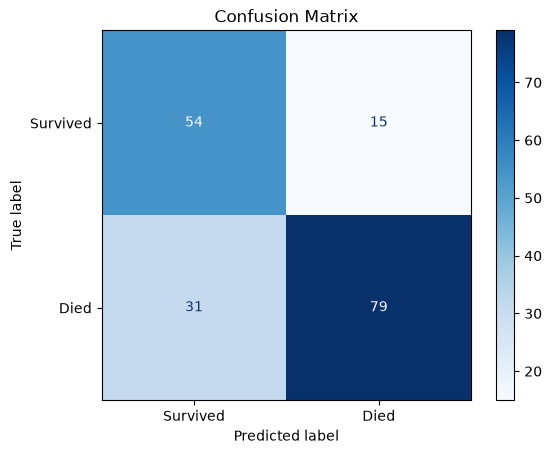

Sex_female    0.608666
Pclass        0.178035
Age           0.112780
FamilySize    0.054535
Fare          0.040513
SibSp         0.005470
IsAlone       0.000000
Parch         0.000000
Embarked_C    0.000000
Embarked_Q    0.000000
dtype: float64


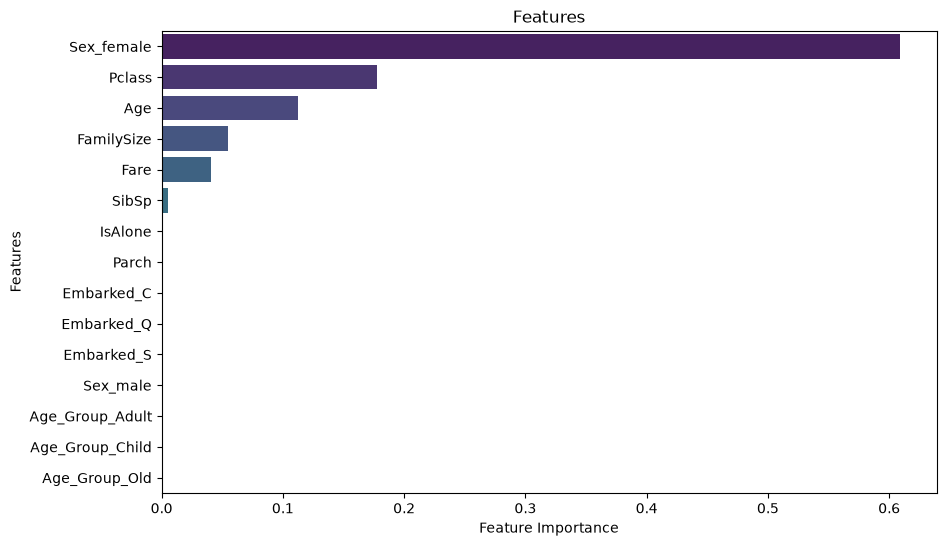

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

tree = Pipeline([
    ("prep", preprocessor),
    ("model", DecisionTreeClassifier(
        max_depth=4,
        min_samples_leaf=4,
        class_weight='balanced',
        random_state=RANDOM_STATE
    ))
])

tree.fit(X_train, y_train)
pred = tree.predict(X_test)

probas = tree.predict_proba(X_test)[:, 1]

train_pred = tree.predict(X_train)

cm = confusion_matrix(y_test, pred, labels=[1, 0])

print("Train Accuracy: ", accuracy_score(y_train, train_pred))
print("Train Precision: ", precision_score(y_train, train_pred))
print("Train Recall: ", recall_score(y_train, train_pred))
print("Train F1: ", f1_score(y_train, train_pred))

print("Accuracy: ", accuracy_score(y_test, pred))
print("Precision: ", precision_score(y_test, pred))
print("Recall: ", recall_score(y_test, pred))
print("F1: ", f1_score(y_test, pred))
print("ROC AUC: ", roc_auc_score(y_test, probas))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=["Survived", "Died"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

show_feature_importance(tree)

models["tree"] = tree

При данных гиперпараметрах метрика F1 примерна равна 0.753. Это выше, чем в примере, возможно, из-за чуть более сложного заполнения пропущенного возвраста: в примере просто медиана, тут медиана внутри соответсвующей группы. Конечно, на train модель справляется лучше, но разврыв с тест не такой большой, поэтому переобучение не слишком сильное. Для модели "наибольшую важность" имеет признак является ли человек женщиной.

## Random forest

Train Accuracy:  0.8525280898876404
Train Precision:  0.8088235294117647
Train Recall:  0.8058608058608059
Train F1:  0.8073394495412844
Accuracy:  0.8379888268156425
Precision:  0.7941176470588235
Recall:  0.782608695652174
F1:  0.7883211678832117
ROC AUC:  0.8534914361001318


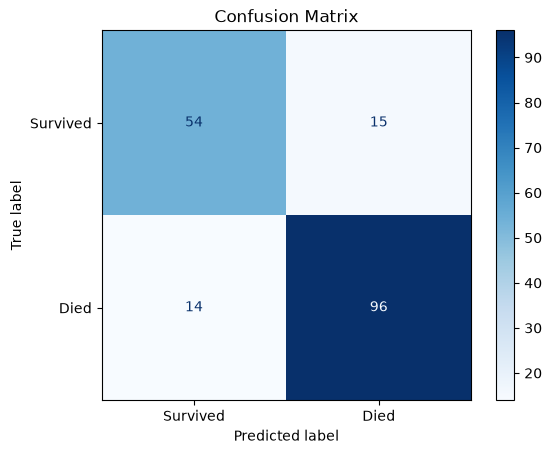

Sex_female         0.269715
Sex_male           0.251402
Fare               0.140344
Pclass             0.111306
Age                0.081147
FamilySize         0.044116
Embarked_S         0.019586
SibSp              0.017806
Age_Group_Child    0.014275
IsAlone            0.013274
dtype: float64


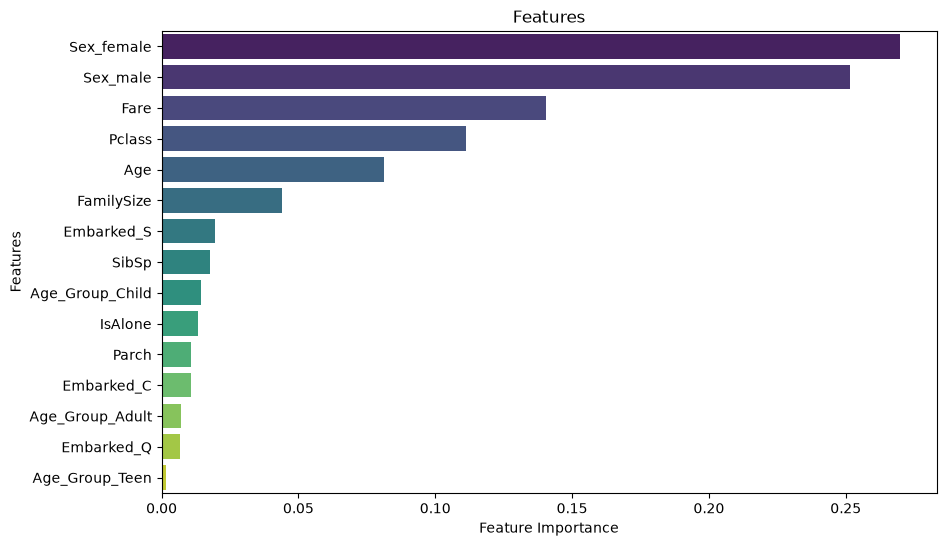

In [24]:
from sklearn.ensemble import RandomForestClassifier

random_forest = Pipeline([
    ("prep", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=500,
        min_samples_leaf=9,
        max_depth=9,
        class_weight='balanced',
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ))
])


random_forest.fit(X_train, y_train)
pred = random_forest.predict(X_test)

train_pred = random_forest.predict(X_train)

probas = random_forest.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, pred, labels=[1, 0])

print("Train Accuracy: ", accuracy_score(y_train, train_pred))
print("Train Precision: ", precision_score(y_train, train_pred))
print("Train Recall: ", recall_score(y_train, train_pred))
print("Train F1: ", f1_score(y_train, train_pred))

print("Accuracy: ", accuracy_score(y_test, pred))
print("Precision: ", precision_score(y_test, pred))
print("Recall: ", recall_score(y_test, pred))
print("F1: ", f1_score(y_test, pred))
print("ROC AUC: ", roc_auc_score(y_test, probas))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=["Survived", "Died"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

show_feature_importance(random_forest)

models["random forest"] = random_forest

К наиболее важным ещё добавлся и мужской пол. Цена билета поднялась выше, а так же, намного больше признаков теперь учитывается.

## Gradient boosting

Train Accuracy:  0.8679775280898876
Train Precision:  0.8744769874476988
Train Recall:  0.7655677655677655
Train F1:  0.81640625
Accuracy:  0.8212290502793296
Precision:  0.8245614035087719
Recall:  0.6811594202898551
F1:  0.746031746031746
ROC AUC:  0.8326086956521739


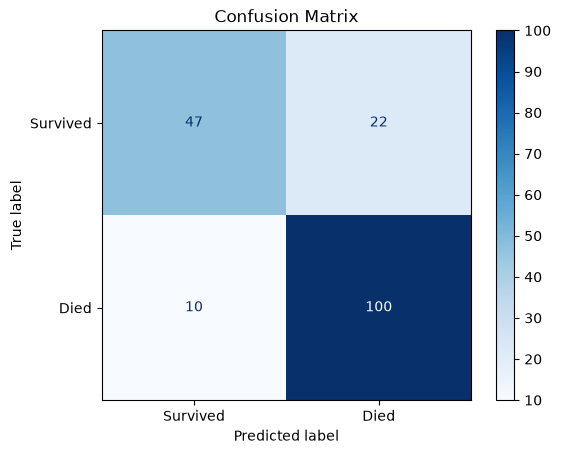

Sex_male      0.259138
Sex_female    0.226041
Pclass        0.161777
Age           0.143491
Fare          0.129249
FamilySize    0.052312
Embarked_S    0.015705
SibSp         0.005994
Parch         0.002504
Embarked_Q    0.002131
dtype: float64


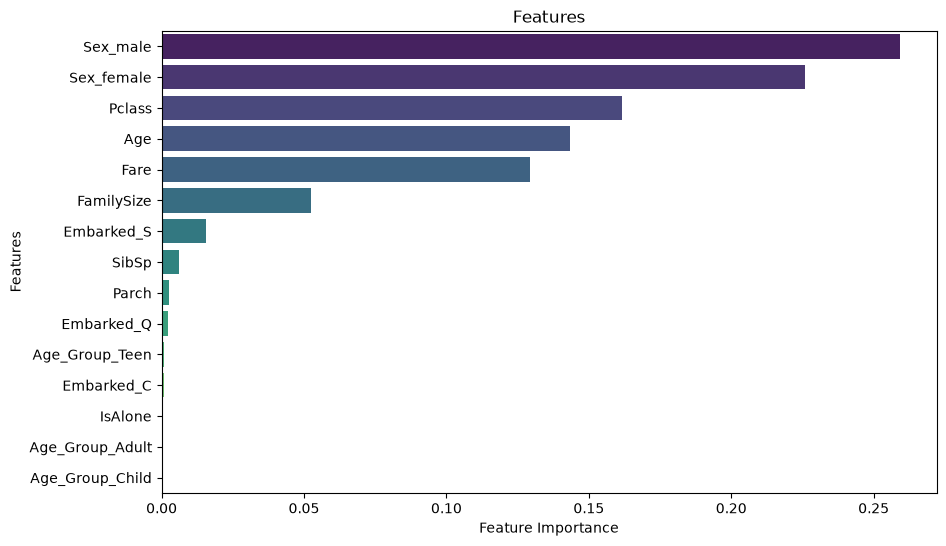

In [25]:
from sklearn.ensemble import GradientBoostingClassifier

gb = Pipeline([
    ("prep", preprocessor),
    ("model", GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        subsample=0.8,
        max_depth=2,
        min_samples_leaf=5,
        random_state=RANDOM_STATE
    ))
])

gb.fit(X_train, y_train)

pred = gb.predict(X_test)
train_pred = gb.predict(X_train)

probas = gb.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, pred, labels=[1, 0])

print("Train Accuracy: ", accuracy_score(y_train, train_pred))
print("Train Precision: ", precision_score(y_train, train_pred))
print("Train Recall: ", recall_score(y_train, train_pred))
print("Train F1: ", f1_score(y_train, train_pred))

print("Accuracy: ", accuracy_score(y_test, pred))
print("Precision: ", precision_score(y_test, pred))
print("Recall: ", recall_score(y_test, pred))
print("F1: ", f1_score(y_test, pred))
print("ROC AUC: ", roc_auc_score(y_test, probas))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=["Survived", "Died"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()

show_feature_importance(gb)

models["gradient boosting"] = gb

Feature importance похож на лес в топе (но тут опять поменяли цену билета и класс местами). По сравнению со случайным лесом по F1, Accuracy, Recall лес лучше. Но это именно на этом сплите, а если посмотреть в CV, тот там видно, что в среднем бустинг лучше леса в Accuracy и Precision.

## SVM

Train Accuracy:  0.8679775280898876
Train Precision:  0.8744769874476988
Train Recall:  0.7655677655677655
Train F1:  0.81640625
Accuracy:  0.8324022346368715
Precision:  0.8095238095238095
Recall:  0.7391304347826086
F1:  0.7727272727272727
ROC AUC:  0.8511198945981555


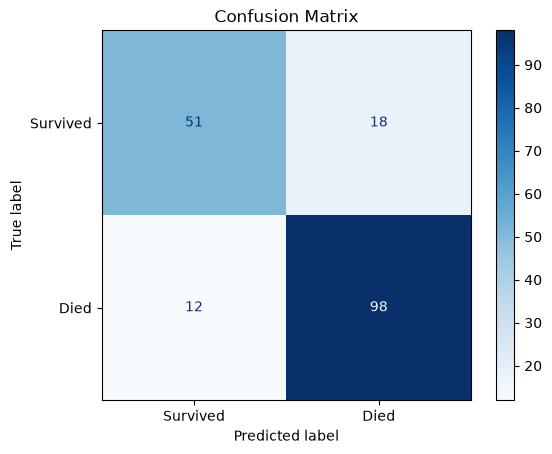

In [26]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler

svc = Pipeline([
    ("prep", preprocessor),
    ("scale", StandardScaler()),
    ("model", SVC(
        C=0.65,
        kernel="rbf",
        gamma="scale",
        class_weight="balanced",
        probability=True
    ))
])

svc.fit(X_train, y_train)
pred = svc.predict(X_test)
pred_train = svc.predict(X_train)

probas = svc.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, pred, labels=[1, 0])

print("Train Accuracy: ", accuracy_score(y_train, train_pred))
print("Train Precision: ", precision_score(y_train, train_pred))
print("Train Recall: ", recall_score(y_train, train_pred))
print("Train F1: ", f1_score(y_train, train_pred))

print("Accuracy: ", accuracy_score(y_test, pred))
print("Precision: ", precision_score(y_test, pred))
print("Recall: ", recall_score(y_test, pred))
print("F1: ", f1_score(y_test, pred))
print("ROC AUC: ", roc_auc_score(y_test, probas))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=["Survived", "Died"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()


models["svc"] = svc

## KNN

Train Accuracy:  0.8679775280898876
Train Precision:  0.8744769874476988
Train Recall:  0.7655677655677655
Train F1:  0.81640625
Accuracy:  0.8044692737430168
Precision:  0.7575757575757576
Recall:  0.7246376811594203
F1:  0.7407407407407407
ROC AUC:  0.8471673254281951


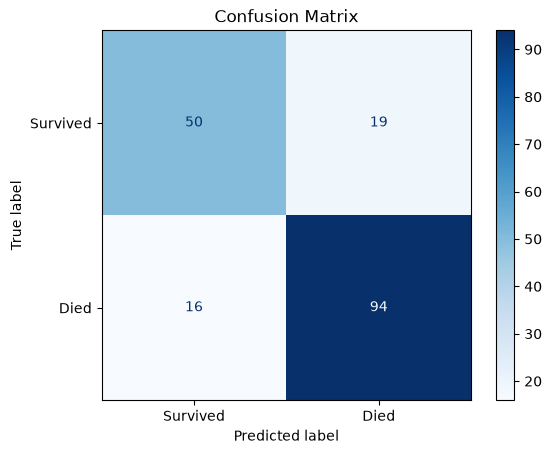

In [27]:
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline([
    ("prep", preprocessor),
    ("scale", StandardScaler()),
    ("model", KNeighborsClassifier(
        n_neighbors=7,
        weights="distance"
    ))
])

knn.fit(X_train, y_train)

pred = knn.predict(X_test)

pred_train = knn.predict(X_train)

probas = knn.predict_proba(X_test)[:, 1]

cm = confusion_matrix(y_test, pred, labels=[1, 0])

print("Train Accuracy: ", accuracy_score(y_train, train_pred))
print("Train Precision: ", precision_score(y_train, train_pred))
print("Train Recall: ", recall_score(y_train, train_pred))
print("Train F1: ", f1_score(y_train, train_pred))

print("Accuracy: ", accuracy_score(y_test, pred))
print("Precision: ", precision_score(y_test, pred))
print("Recall: ", recall_score(y_test, pred))
print("F1: ", f1_score(y_test, pred))
print("ROC AUC: ", roc_auc_score(y_test, probas))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=["Survived", "Died"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix")
plt.show()


models["knn"] = knn


## CV

In [28]:
import warnings

from sklearn.exceptions import UndefinedMetricWarning
from sklearn.model_selection import StratifiedKFold, cross_validate

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

cv = StratifiedKFold(shuffle=True, random_state=RANDOM_STATE)

scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1'
}

def test_model(model): 
    res = cross_validate(
        model,
        X_train, y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False
    )

    return res

for name, model in models.items():
    display(name)
    results = test_model(model)

    print(f"Mean Accuracy:  {results['test_accuracy'].mean():.4f}")
    print(f"Mean Precision: {results['test_precision'].mean():.4f}")
    print(f"Mean Recall:    {results['test_recall'].mean():.4f}")
    print(f"Mean F1:        {results['test_f1'].mean():.4f}")


'dummy'

Mean Accuracy:  0.6166
Mean Precision: 0.0000
Mean Recall:    0.0000
Mean F1:        0.0000


'tree'

Mean Accuracy:  0.7880
Mean Precision: 0.7214
Mean Recall:    0.7434
Mean F1:        0.7298


'random forest'

...

Mean Accuracy:  0.8047
Mean Precision: 0.7836
Mean Recall:    0.6922
Mean F1:        0.7310


'svc'

Mean Accuracy:  0.8090
Mean Precision: 0.7746
Mean Recall:    0.7143
Mean F1:        0.7418


'knn'

Mean Accuracy:  0.7977
Mean Precision: 0.7461
Mean Recall:    0.7216
Mean F1:        0.7324


## Сравнение моделей

In [29]:
metrics_data = []

for name, model in models.items():
    pred = model.predict(X_test)
    
    metrics_data.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred)
    })

df_metrics = pd.DataFrame(metrics_data)

df_metrics.set_index("Model", inplace=True)
df_metrics = df_metrics.sort_values(by="F1", ascending=False)

display(df_metrics)


,Accuracy,Precision,Recall,F1
Model,,,,
random forest,0.837989,0.794118,0.782609,0.788321
svc,0.832402,0.809524,0.739130,0.772727
gradient boosting,0.821229,0.824561,0.681159,0.746032
knn,0.804469,0.757576,0.724638,0.740741
tree,0.743017,0.635294,0.782609,0.701299
dummy,0.614525,0.000000,0.000000,0.000000


Все модели, кроме dummy превзошли установленный порог. Одиночные деревья сколнны к переобучению и нестабильны, случайный лес это исправляет. У градиентного бустинга самый точный precision, так как он как раз учится на ошибках, но "боится" причислять людей к выжившим.

## Kaggle

In [30]:
import pandas as pd

test_df = pd.read_csv("./test.csv")

test_ids = test_df["Id"]

selected_model = random_forest

selected_model.fit(X, y)

predictions = selected_model.predict(test_df)

submission = pd.DataFrame({
    "Id": test_ids,
    "Survived": predictions
})

submission.to_csv("submission.csv", index=False)

display(submission.head(10))

,Id,Survived
0,55586928,0
1,24554381,0
2,50120493,1
3,16342593,0
4,10829305,0
5,83246335,1
6,30438485,0
7,10535504,0
8,41653622,0
9,18173921,1


In [31]:
import pandas as pd

test_df = pd.read_csv("./test.csv")

test_ids = test_df["Id"]

selected_model = random_forest

selected_model.fit(X, y)

predictions = selected_model.predict(test_df)

submission = pd.DataFrame({
    "Id": test_ids,
    "Survived": predictions
})

submission.to_csv("submission.csv", index=False)

display(submission.head(10))

,Id,Survived
0,55586928,0
1,24554381,0
2,50120493,1
3,16342593,0
4,10829305,0
5,83246335,1
6,30438485,0
7,10535504,0
8,41653622,0
9,18173921,1


## Feature importance

Графики выше. По ним видно, что важными признаками явлются пол, тариф, возвраст. На остальные места можно посмотреть на графиках выше. 


jПричиной выживания не является, к примеру, пол, просто спаслось больше женщин.

In [32]:
pred = random_forest.predict(X_test)

tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()

print("TP:", tp)
print("TN:", tn)
print("FP:", fp)
print("FN:", fn)

errors_df = X_test.copy()
errors_df['Actual'] = y_test
errors_df['Predicted'] = pred

misclassified = errors_df[errors_df['Actual'] != errors_df['Predicted']]

display(misclassified[['Name', 'Sex', 'Age', 'Pclass', 'Fare', 'Actual', 'Predicted']])

TP: 56
TN: 96
FP: 14
FN: 13


,Name,Sex,Age,Pclass,Fare,Actual,Predicted
553,"Leeni, Mr. Fahim (""Philip Zenni"")",male,22.0,3,7.2250,1,0
536,"Butt, Major. Archibald Willingham",male,45.0,1,26.5500,0,1
698,"Thayer, Mr. John Borland",male,49.0,1,110.8833,0,1
712,"Taylor, Mr. Elmer Zebley",male,48.0,1,52.0000,1,0
455,"Jalsevac, Mr. Ivan",male,29.0,3,7.8958,1,0
65,"Moubarek, Master. Gerios",male,NaN,3,15.2458,1,0
297,"Allison, Miss. Helen Loraine",female,2.0,1,151.5500,0,1
40,"Ahlin, Mrs. Johan (Johanna Persdotter Larsson)",female,40.0,3,9.4750,0,1
564,"Meanwell, Miss. (Marion Ogden)",female,NaN,3,8.0500,0,1
502,"O'Sullivan, Miss. Bridget Mary",female,NaN,3,7.6292,0,1


Всего 27 ошибок на тестовых данных. Видна одна вещь - модель ошибается на "спорных" пассажирах - допустим, сверху есть такой пример, где на похожих мужчин он ответил по-разному. Я думаю, что модель заметила, что при 1 классе с дешёвым билетом люди чаще выживают (наверное) (допустим, VIP персоны) и поэтому Батту предрекла жизнь. А на Тейлоре по цене, возможно, проходила грань.